# Step 2 — Baseline: PPO on Walker-v0 with the hand-designed robot

**Setup:** course TD6 hyperparameters (lr 3e-4, γ 0.99, λ 0.95, clip 0.2, 10 epochs, batch 64, 2048 transitions per update), **no reward normalisation**, 1M steps, 8 parallel envs, seed 31.

Training was launched from the terminal (this notebook only analyses the saved run):
```bash
caffeinate -i python ppo.py --env Walker-v0 --robot walker --steps 1000000 --n-envs 8 \
    --vectorization async --seed 31 --out runs/walker_baseline_s31
```

**Robot** (5×5 voxels: 1 rigid, 3 horizontal muscle, 4 vertical muscle, 0 empty) — a rigid back and two legs, seen from the side. It is only a fixed problem to tune PPO and a human reference to beat; it is never part of the evolution.
```
1 1 1 1 1
3 3 3 3 3
3 3 . 3 3
4 4 . 4 4
4 4 . 4 4
```
**Task:** move right as far as possible; reward ≈ forward displacement of the robot per step; episodes of 500 steps.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, "..")  # repo root, where ppo.py lives
from ppo import PPOAgent, make_env, load_body, test_agent

RUN = Path("../runs/walker_baseline_s31")
config = json.loads((RUN / "config.json").read_text())
log = pd.read_csv(RUN / "log.csv")
episodes = pd.read_csv(RUN / "episodes.csv")["episode_return"].to_numpy()
body = np.array(config["body"])
print(f"{config['steps']:,} steps, {len(episodes)} episodes, {log['time_s'].iloc[-1] / 60:.1f} min of training")
print(body)

1,000,000 steps, 2120 episodes, 13.2 min of training
[[1 1 1 1 1]
 [3 3 3 3 3]
 [3 3 0 3 3]
 [4 4 0 4 4]
 [4 4 0 4 4]]


## Random reference

What does a "zero" score look like on this task? Same robot, uniformly random actions, 10 episodes.

In [2]:
env = make_env("Walker-v0", {"body": body})
env.action_space.seed(0)
random_returns = []
for ep in range(10):
    env.reset(seed=ep)
    done, total = False, 0.0
    while not done:
        _, r, terminated, truncated, _ = env.step(env.action_space.sample())
        total += r
        done = terminated or truncated
    random_returns.append(total)
env.close()
random_mean, random_std = np.mean(random_returns), np.std(random_returns)
print(f"Random actions: {random_mean:.3f} ± {random_std:.3f} per episode")

/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/evogym/envs/base.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Random actions: -0.020 ± 0.237 per episode


## Learning curves

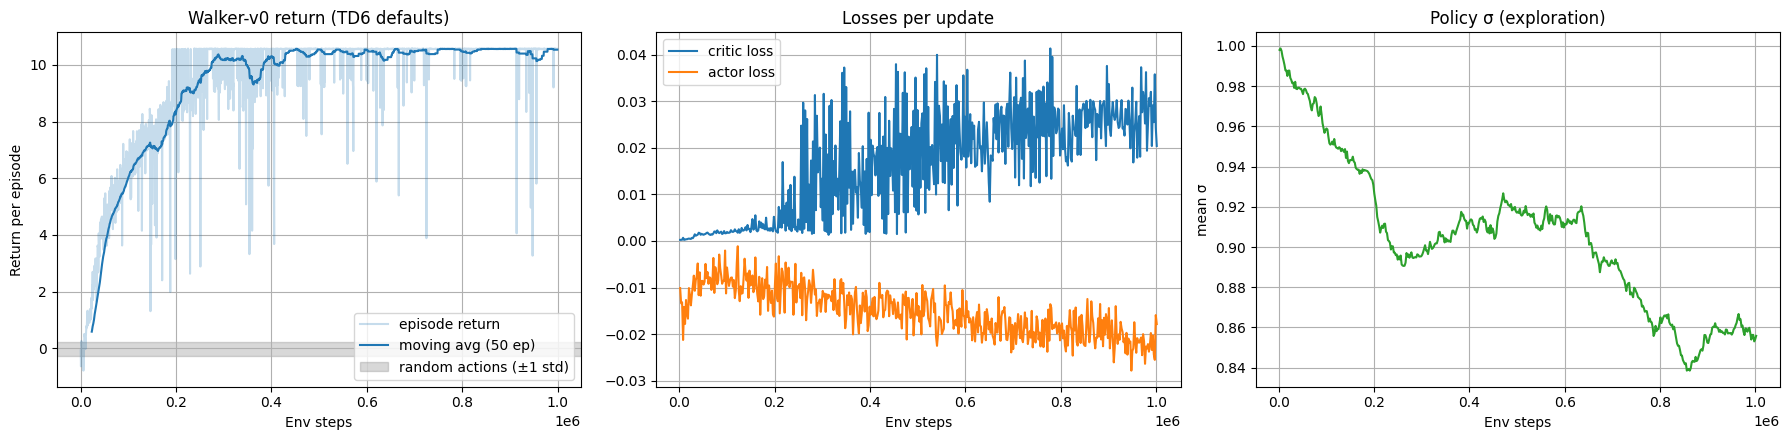

Last 100 episodes: 10.50 ± 0.49 | best moving avg (50): 10.57 | random: -0.02


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
steps_per_episode = config["steps"] / len(episodes)

ax = axes[0]
x = np.arange(len(episodes)) * steps_per_episode
ax.plot(x, episodes, alpha=0.25, color="tab:blue", label="episode return")
w = 50
ax.plot(x[w - 1:], np.convolve(episodes, np.ones(w) / w, "valid"), color="tab:blue", label=f"moving avg ({w} ep)")
ax.axhspan(random_mean - random_std, random_mean + random_std, color="gray", alpha=0.3, label="random actions (±1 std)")
ax.set(title="Walker-v0 return (TD6 defaults)", xlabel="Env steps", ylabel="Return per episode")
ax.legend(); ax.grid(True)

ax = axes[1]
ax.plot(log["steps"], log["critic_loss"], label="critic loss")
ax.plot(log["steps"], log["actor_loss"], label="actor loss")
ax.set(title="Losses per update", xlabel="Env steps"); ax.legend(); ax.grid(True)

ax = axes[2]
ax.plot(log["steps"], log["sigma"], color="tab:green")
ax.set(title="Policy σ (exploration)", xlabel="Env steps", ylabel="mean σ"); ax.grid(True)

plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
plt.savefig("../figures/02_walker_baseline.png", dpi=120)
plt.show()

print(f"Last 100 episodes: {episodes[-100:].mean():.2f} ± {episodes[-100:].std():.2f} | "
      f"best moving avg ({w}): {np.convolve(episodes, np.ones(w) / w, 'valid').max():.2f} | random: {random_mean:.2f}")

## Trained robot (deterministic policy) + GIF

The GIF uses EvoGym's default renderer (the custom renderer is step 7).

In [4]:
obs_size = make_env("Walker-v0", {"body": body}).observation_space.shape[0]
agent = PPOAgent(state_size=obs_size, action_size=int((body >= 3).sum()))
agent.network.load_state_dict(torch.load(RUN / "model.pt"))
agent.network.eval()

test_returns = test_agent(agent, env_id="Walker-v0", episodes=5, env_kwargs={"body": body},
                          gif_path="../figures/02_walker_baseline.gif")
print(f"Deterministic test: {np.mean(test_returns):.2f} ± {np.std(test_returns):.2f} (random: {random_mean:.2f})")

Using device: cpu


/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:426: UserWarning: WARN: No render fps was declared in the environment (env.metadata['render_fps'] is None or not defined), rendering may occur at inconsistent fps.
  logger.warn(


Test Episode 1: 10.55


Test Episode 2: 10.55


Test Episode 3: 10.55


Test Episode 4: 10.55


Test Episode 5: 10.55


Deterministic test: 10.55 ± 0.00 (random: -0.02)


![](../figures/02_walker_baseline.gif)

## Analysis

**It learns, fast.** The robot goes from the random level (−0.02 ± 0.24) to **10.50 ± 0.49** over the last 100 episodes (deterministic test: **10.55**). Most of the progress happens in the first 250k steps (avg100 ≈ 5.3 at 100k, 8.9 at 250k, 10.4 at 500k), in 13 minutes of training.

**But the score saturates — and that is a property of the task, not of PPO.** In `Walker-v0` the reward is the forward displacement of the robot's centre of mass, and the episode **ends with a +1 bonus once the robot reaches x = 9.9** (end of the track). The maximum possible return is therefore ≈ 10.5, and the robot hits it from ~400k steps on: the curve is flat because there is nothing left to gain, not because learning stalls.

Consequences for the next steps:
1. **Return alone can no longer separate two good agents.** Better metrics for the optimisation experiments (step 4) and for the evolution fitness (step 5):
   - **steps needed to reach the goal** (deterministic policy: **387 / 500** for this baseline — lower = faster robot),
   - **sample efficiency**: env steps of training before the agent first reaches the goal reliably (here ≈ 400k).
2. The **critic loss grows** after 200k steps while the actor keeps improving, and **σ only drops from 1.0 to 0.85**: the policy is still very noisy, the occasional drops of the light-blue curve are exploration noise. A reduced σ or a faster robot are possible improvements — to test in step 4.

**Still to check (step 3):** other seeds (only seed 31 here), and whether reward normalisation behaves like on Pendulum — here rewards are tiny (≈ 0.02 per step), the opposite scale problem.